# Real-space overlap is not enough: ambiguity in nanobeam iterative ptychography

**Scan 23: Iterative reconstruction**

**Authors:** Stephanie M. Ribet, Mohsen Danaie, Willem P.M. de Kleijne, Arthur R. C. McCray, Frederick Allars, Christopher S. Allen, Colin Ophus, Georgios Varnavides

**Affiliations:**
- National Center for Electron Microscopy, Molecular Foundry, Lawrence Berkeley National Laboratory
- Electron Physical Sciences Imaging Centre, Diamond Light Source
- Department of Imaging Physics, Delft University of Technology
- Department of Materials Science and Engineering, Stanford University

In [1]:
%load_ext autoreload 
%autoreload 2

In [2]:
import numpy as np

import quantem as em
from quantem.core import config
from quantem.core.visualization import show_2d
import matplotlib.pyplot as plt

# load data

In [4]:
probe_semiangle = 24
energy = 300e3

In [5]:
dirpath = ""
filepath_data = dirpath + "nanobeam_ptycho_23_master.h5"
dc = em.io.read_4dstem(filepath_data, file_type="arina")
print(dc)

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 192, 192)
  dtype: uint16
  device: cpu
  origin: [0. 0. 0. 0.]
  sampling: [0.47470101 0.47470101 1.         1.        ]
  units: ['A', 'A', 'pixels', 'pixels']
  signal units: 'arb. units'


In [6]:
dc.array.sum((3,2)).mean()

np.float64(87437.94832229614)

In [7]:
dc.bin(2, axes= (2,3), modify_in_place=True)

In [8]:
im =  dc.array.sum((-1,-2))

(<Figure size 400x400 with 1 Axes>, <Axes: >)

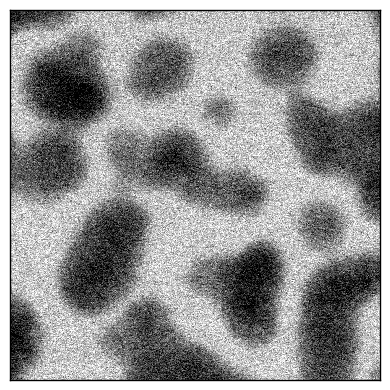

In [9]:
show_2d(
   im
)

# calibrate

In [10]:
dc.get_dp_mean()

Dataset(shape=(96, 96), dtype=float64, name='4D-STEM dataset_dp_mean')
  sampling: [2. 2.]
  units: ['pixels', 'pixels']
  signal units: 'arb. units'

(<Figure size 1200x400 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >], dtype=object))

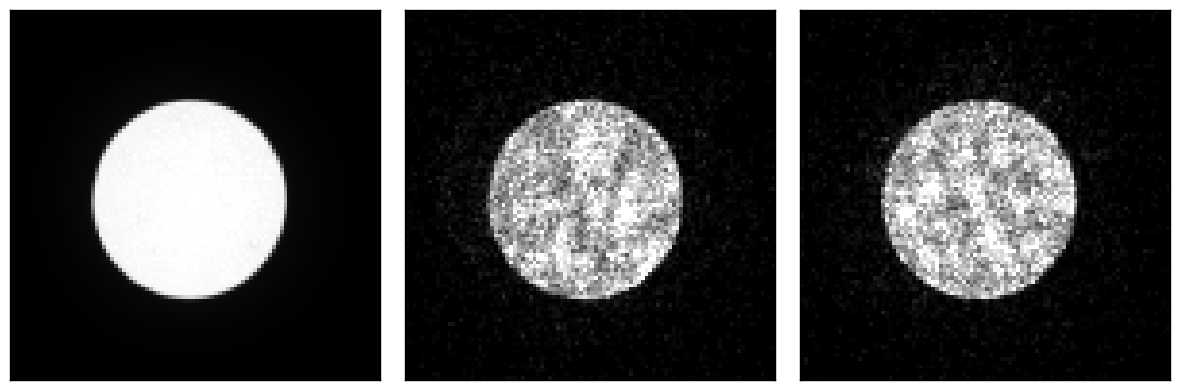

In [11]:
em.visualization.show_2d(
    [
        dc.dp_mean,
        dc.array[128,128],
        dc.array[256,256]
    ]
)

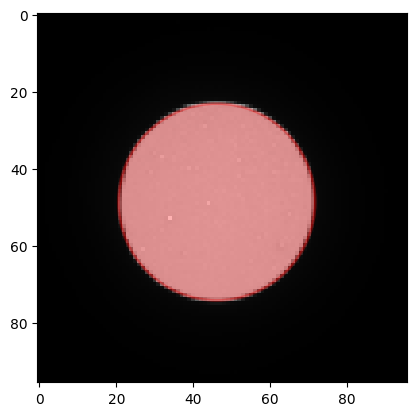

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 96, 96)
  dtype: uint64
  device: cpu
  origin: [0.  0.  0.5 0.5]
  sampling: [0.47470101 0.47470101 0.93246184 0.93246184]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'


In [12]:
from quantem.core.utils.diffractive_imaging_utils import fit_probe_circle
probe_qy0, probe_qx0, probe_R = fit_probe_circle(dc.dp_mean.array, show=True)
dc.sampling[2] = 0.93246184
dc.sampling[3] = 0.93246184
dc.units[2:] = ["mrad", "mrad"]

print(dc)

In [13]:
probe_R

np.float64(25.575523687846196)

# iterative ptycho

In [14]:
from quantem.core.datastructures import Dataset4dstem
from quantem.diffractive_imaging.dataset_models import PtychographyDatasetRaster
from quantem.diffractive_imaging.ptychography_lite import PtychoLite, PtychoLiteDIP

In [15]:
dc_crop = dc.copy().crop(((0, 10), (0,10)), axes = (0,1))

Forcing best fit rotation to -169 degrees.
Forcing transpose of intensities to False.


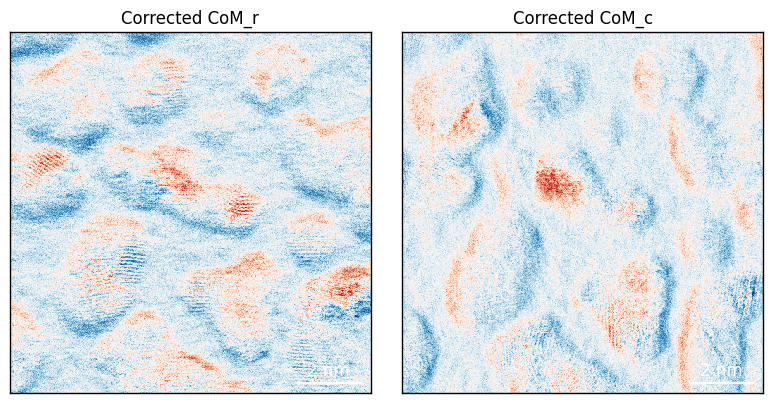

Normalizing intensities:   0%|          | 0/262144 [00:00<?, ?probe position/s]

In [ ]:
pdset = PtychographyDatasetRaster.from_dataset4dstem(dc)

pdset.preprocess(
    com_fit_function="constant",
    plot_rotation=True,
    plot_com=True,
    probe_energy=energy,
    force_com_rotation=-169,
    force_com_transpose = False,
)

In [ ]:
ptycho_pix = PtychoLite.from_dataset(
    dset=pdset,
    num_slices=1,
    obj_type="complex",
    num_probes=4,
    energy=energy,
    semiangle_cutoff=probe_semiangle,
    obj_padding_px=(32,32),
    device="cpu",
    polar_parameters = {
        'C10':  -176.7006242519572,
    },
)

In [ ]:
ptycho_pix.logger = None

Iter 50/50, Loss: 8.281e+03: 100%|███████████████████| 50/50 [04:16<00:00,  5.13s/it]


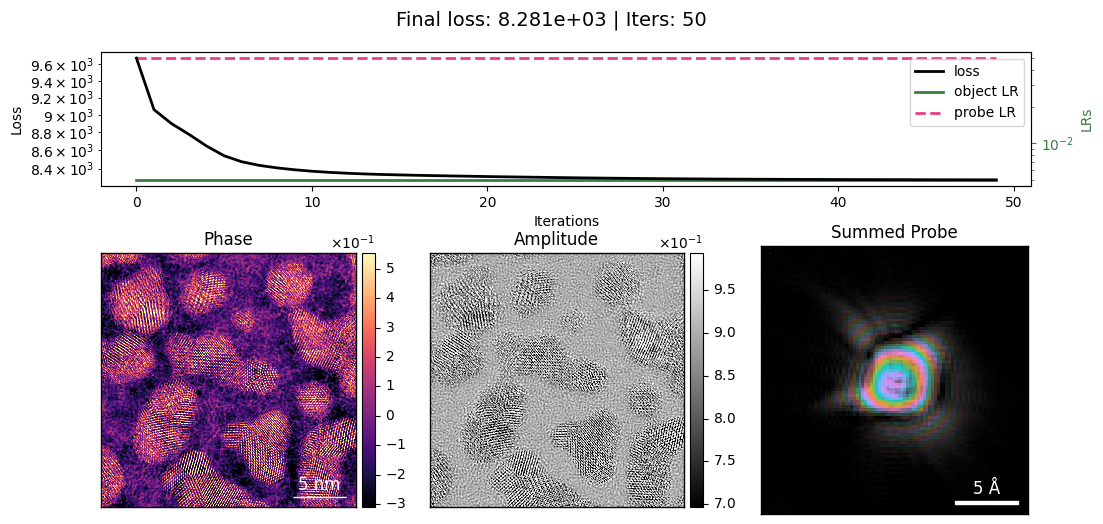

In [19]:
constraints = {
    "object":{
        "identical_slices": True,
    },
    "probe":{
         "orthogonalize_probe": False
    },
}
ptycho_pix.reconstruct(
    num_iters=50, 
    device=[0,1,2], 
    batch_size=512 * 3,
    constraints=constraints,
    reset = True,
    lr_obj = 5e-3,
    lr_probe = 5e-2,
).visualize()

In [20]:
import h5py

with h5py.File('recons/scan_23_direct_ptycho_260522.h5', 'r') as f:
    direct_ptycho_obj = f['obj'][()]
    sampling = f['sampling'][()]

(<Figure size 1200x600 with 2 Axes>, array([<Axes: >, <Axes: >], dtype=object))

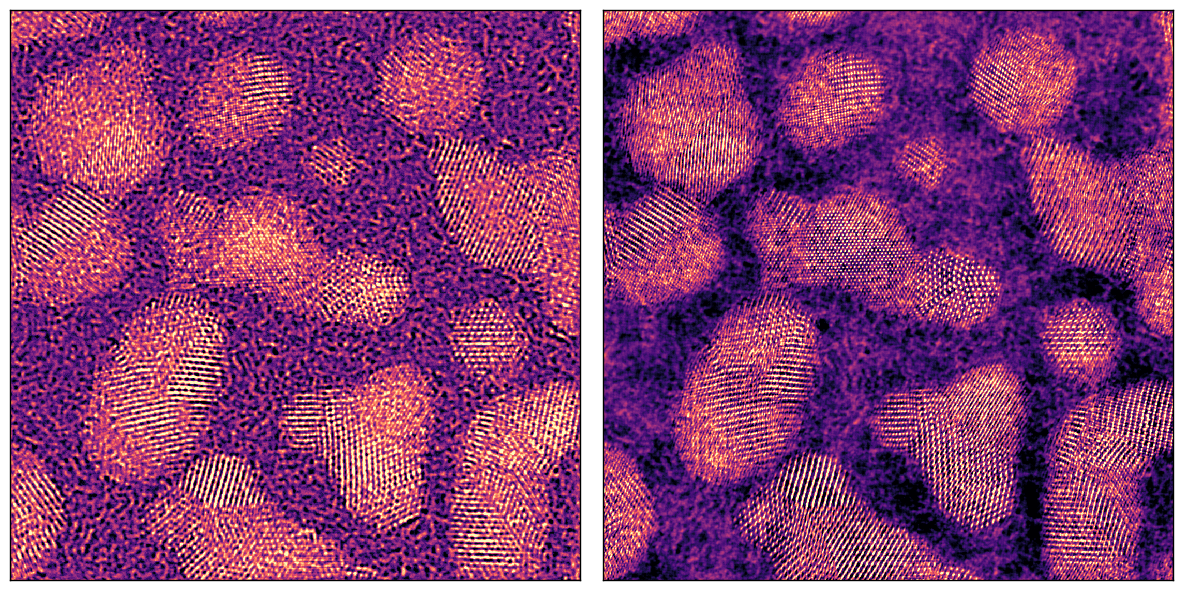

In [21]:
em.visualization.show_2d(
    [
        direct_ptycho_obj,
        np.angle(ptycho_pix.obj_cropped)[0],
    ],
    axsize = (6,6),
    cmap = "magma"
)

In [22]:
with h5py.File('recons/260630_scan_23_pix_ptycho.h5', 'w') as f:
    f.create_dataset('obj', data = ptycho_pix.obj_cropped)
    f.create_dataset('sampling', data = ptycho_pix.sampling)
    f.create_dataset('probe', data = ptycho_pix.probe)

In [ ]:
import torch 
import gc
torch.cuda.empty_cache()
gc.collect()

In [ ]:
ptycho_dip = PtychoLiteDIP.from_ptycholite(
    ptycholite=ptycho_pix,
    pretrain_iters=150,
    pretrain_object_lr = 2.5e-3,
    device="gpu",
)

In [ ]:
torch.cuda.empty_cache()
gc.collect()

ptycho_dip.reconstruct(
    num_iters=50, 
    reset=True, 
    scheduler_type='plateau', 
    batch_size=200,
    lr_obj = 1e-5,
    lr_probe = 1e-3,
    device=[0,1,2], 
    constraints=constraints,
).visualize()

In [ ]:
ptycho_dip.visualize()

In [ ]:
em.visualization.show_2d(
    [
        direct_ptycho_obj, 
        np.angle(ptycho_pix.obj_cropped)[0],
        np.angle(ptycho_dip.obj_cropped)[0],
    ],
    axsize = (6,6),
    cmap = "magma"
)

In [ ]:
ptycho_dip.show_probe()

In [ ]:
ptycho_dip.show_fourier_probe()

In [ ]:
with h5py.File('recons/260630_scan_23_dip_ptycho.h5', 'w') as f:
    f.create_dataset('obj', data = ptycho_dip.obj_cropped)
    f.create_dataset('sampling', data = ptycho_dip.sampling)
    f.create_dataset('probe', data = ptycho_dip.probe)